In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.metrics import silhouette_score, davies_bouldin_score, adjusted_rand_score
from sklearn.cluster import KMeans
from sklearn.mixture import GaussianMixture
from sklearn.decomposition import PCA

In [2]:
df = pd.read_csv('SouthGermanCredit.asc', sep=r'\s+')
df.head()

,laufkont,laufzeit,moral,verw,hoehe,sparkont,beszeit,rate,famges,buerge,...,verm,alter,weitkred,wohn,bishkred,beruf,pers,telef,gastarb,kredit
0,1,18,4,2,1049,1,2,4,2,1,...,2,21,3,1,1,3,2,1,2,1
1,1,9,4,0,2799,1,3,2,3,1,...,1,36,3,1,2,3,1,1,2,1
2,2,12,2,9,841,2,4,2,2,1,...,1,23,3,1,1,2,2,1,2,1
3,1,12,4,0,2122,1,3,3,3,1,...,1,39,3,1,2,2,1,1,1,1
4,1,12,4,0,2171,1,3,4,3,1,...,2,38,1,2,2,2,2,1,1,1


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 21 columns):
 #   Column    Non-Null Count  Dtype
---  ------    --------------  -----
 0   laufkont  1000 non-null   int64
 1   laufzeit  1000 non-null   int64
 2   moral     1000 non-null   int64
 3   verw      1000 non-null   int64
 4   hoehe     1000 non-null   int64
 5   sparkont  1000 non-null   int64
 6   beszeit   1000 non-null   int64
 7   rate      1000 non-null   int64
 8   famges    1000 non-null   int64
 9   buerge    1000 non-null   int64
 10  wohnzeit  1000 non-null   int64
 11  verm      1000 non-null   int64
 12  alter     1000 non-null   int64
 13  weitkred  1000 non-null   int64
 14  wohn      1000 non-null   int64
 15  bishkred  1000 non-null   int64
 16  beruf     1000 non-null   int64
 17  pers      1000 non-null   int64
 18  telef     1000 non-null   int64
 19  gastarb   1000 non-null   int64
 20  kredit    1000 non-null   int64
dtypes: int64(21)
memory usage: 164.2 KB


In [4]:
# Проверяем пропуски
df.isna().sum()

laufkont    0
laufzeit    0
moral       0
verw        0
hoehe       0
sparkont    0
beszeit     0
rate        0
famges      0
buerge      0
wohnzeit    0
verm        0
alter       0
weitkred    0
wohn        0
bishkred    0
beruf       0
pers        0
telef       0
gastarb     0
kredit      0
dtype: int64

In [5]:
# Проверяем полные повторы строк
df.duplicated().sum()

np.int64(0)

In [6]:
# Изучаем диапазоны количественных признаков
numeric_cols = ['laufzeit', 'hoehe', 'alter']
df[numeric_cols].describe()

,laufzeit,hoehe,alter
count,1000.000000,1000.00000,1000.00000
mean,20.903000,3271.24800,35.54200
std,12.058814,2822.75176,11.35267
min,4.000000,250.00000,19.00000
25%,12.000000,1365.50000,27.00000
50%,18.000000,2319.50000,33.00000
75%,24.000000,3972.25000,42.00000
max,72.000000,18424.00000,75.00000


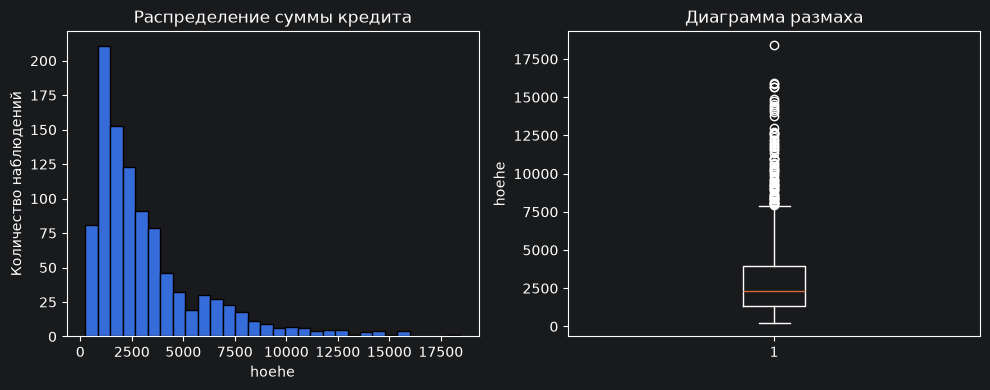

In [7]:
# Строим график, хочу посмотреть на распределение суммы кредита
# Вижу что фича hoehe имеет правостороннюю асимметрию:
# mean - 3271.25, 50% - 2319.5
fig, ax = plt.subplots(1, 2, figsize=(10, 4))

ax[0].hist(df['hoehe'], bins=30, edgecolor='black')
ax[0].set_xlabel('hoehe')
ax[0].set_ylabel('Количество наблюдений')
ax[0].set_title('Распределение суммы кредита')

ax[1].boxplot(df['hoehe'])
ax[1].set_ylabel('hoehe')
ax[1].set_title('Диаграмма размаха')

plt.tight_layout()
plt.show()

In [8]:
# Делим датасет, 60/20/20
x = df.drop(columns='kredit')
y = df['kredit']

x_train_val, x_test, y_train_val, y_test = train_test_split(
    x, y, test_size=0.2, random_state=42
)

x_train, x_val, y_train, y_val = train_test_split(
    x_train_val, y_train_val, test_size=0.25, random_state=42
)

print(x_train.shape, x_val.shape, x_test.shape)

(600, 20) (200, 20) (200, 20)


In [9]:
# Создаем новую фичу, логарифм hoehe, чтобы сжать диапазон больших значений
x_train['hoehe_log'] = np.log1p(x_train['hoehe'])
x_val['hoehe_log'] = np.log1p(x_val['hoehe'])
x_test['hoehe_log'] = np.log1p(x_test['hoehe'])

In [10]:
# Масштабируем и кодируем, обучаем только на train
numeric_cols = ['laufzeit', 'alter', 'hoehe_log']

categorical_cols = x_train.columns.drop(
    numeric_cols + ['hoehe']
).tolist()

preprocessor = ColumnTransformer([
    ('num', StandardScaler(), numeric_cols),
    ('cat', OneHotEncoder(
        handle_unknown='ignore',
        sparse_output=False
    ), categorical_cols)
])

x_train_ready = preprocessor.fit_transform(x_train)
x_val_ready = preprocessor.transform(x_val)
x_test_ready = preprocessor.transform(x_test)

print(x_train_ready.shape, x_val_ready.shape, x_test_ready.shape)

(600, 71) (200, 71) (200, 71)


In [11]:
# Подбираем число кластеров в полном пространстве фичей
kmeans_results = []

for k in range(2, 11):
    model = KMeans(
        n_clusters=k,
        n_init=10,
        random_state=42
    )
    model.fit(x_train_ready)
    y_val_pred = model.predict(x_val_ready)

    kmeans_results.append({
        'k': k,
        'silhouette': silhouette_score(x_val_ready, y_val_pred),
        'davies_bouldin': davies_bouldin_score(x_val_ready, y_val_pred)
    })

kmeans_results_df = pd.DataFrame(kmeans_results)
kmeans_results_df

,k,silhouette,davies_bouldin
0,2,0.107579,2.691290
1,3,0.082726,2.785572
2,4,0.068557,2.965901
3,5,0.056291,3.047294
4,6,0.048686,3.273506
5,7,0.046441,3.112061
6,8,0.041100,2.994402
7,9,0.041319,2.893575
8,10,0.032146,3.015531


In [12]:
# Подбираем гиперпараметры для GaussianMixture
gmm_results = []

for k in range(2, 11):
    for covariance in ['full', 'tied', 'diag', 'spherical']:
        model = GaussianMixture(
            n_components=k,
            covariance_type=covariance,
            n_init=5,
            random_state=42
        )
        model.fit(x_train_ready)
        y_val_pred = model.predict(x_val_ready)

        n_pred = np.unique(y_val_pred).size

        silhouette = np.nan
        davies_bouldin = np.nan

        if model.converged_ and 2 <= n_pred < len(y_val_pred):
            silhouette = silhouette_score(x_val_ready, y_val_pred)
            davies_bouldin = davies_bouldin_score(x_val_ready, y_val_pred)

        gmm_results.append({
            'k': k,
            'covariance_type': covariance,
            'silhouette': silhouette,
            'davies_bouldin': davies_bouldin,
            'converged': model.converged_
        })

gmm_results_df = pd.DataFrame(gmm_results)

In [13]:
# Теперь посмотрим на silhouette
gmm_results_df.sort_values('silhouette', ascending=False).head(5)

,k,covariance_type,silhouette,davies_bouldin,converged
3,2,spherical,0.107579,2.691290,True
7,3,spherical,0.079718,2.835845,True
11,4,spherical,0.070815,2.829968,True
19,6,spherical,0.047058,3.052285,True
15,5,spherical,0.045532,3.189375,True


In [14]:
# И на Davies-Bouldin
gmm_results_df.sort_values('davies_bouldin').head(5)

,k,covariance_type,silhouette,davies_bouldin,converged
3,2,spherical,0.107579,2.691290,True
28,9,full,-0.035316,2.715788,True
11,4,spherical,0.070815,2.829968,True
35,10,spherical,0.038498,2.834045,True
7,3,spherical,0.079718,2.835845,True


In [15]:
# Лучший результат показал себя k=2 по обоим метрикам
# Обучаем выбранные модели в полном пространстве фичей
kmeans_full = KMeans(
    n_clusters=2,
    n_init=10,
    random_state=42
)
kmeans_full.fit(x_train_ready)

gmm_full = GaussianMixture(
    n_components=2,
    covariance_type='spherical',
    n_init=5,
    random_state=42
)
gmm_full.fit(x_train_ready)

,"n_components n_components: int, default=1The number of mixture components.",2
,"covariance_type covariance_type: {'full', 'tied', 'diag', 'spherical'}, default='full'String describing the type of covariance parameters to use.Must be one of:- 'full': each component has its own general covariance matrix.- 'tied': all components share the same general covariance matrix.- 'diag': each component has its own diagonal covariance matrix.- 'spherical': each component has its own single variance.For an example of using `covariance_type`, refer to:ref:`sphx_glr_auto_examples_mixture_plot_gmm_selection.py`.",'spherical'
,"n_init n_init: int, default=1The number of initializations to perform. The best results are kept.",5
,"random_state random_state: int, RandomState instance or None, default=NoneControls the random seed given to the method chosen to initialize theparameters (see `init_params`).In addition, it controls the generation of random samples from thefitted distribution (see the method `sample`).Pass an int for reproducible output across multiple function calls.See :term:`Glossary <random_state>`.",42
,"tol tol: float, default=1e-3The convergence threshold. EM iterations will stop when thelower bound average gain is below this threshold.",0.001
,"reg_covar reg_covar: float, default=1e-6Non-negative regularization added to the diagonal of covariance.Allows to assure that the covariance matrices are all positive.",1e-06
,"max_iter max_iter: int, default=100The number of EM iterations to perform.",100
,"init_params init_params: {'kmeans', 'k-means++', 'random', 'random_from_data'}, default='kmeans'The method used to initialize the weights, the means and theprecisions.String must be one of:- 'kmeans' : responsibilities are initialized using kmeans.- 'k-means++' : use the k-means++ method to initialize.- 'random' : responsibilities are initialized randomly.- 'random_from_data' : initial means are randomly selected data points... versionchanged:: v1.1 `init_params` now accepts 'random_from_data' and 'k-means++' as initialization methods.",'kmeans'
,"weights_init weights_init: array-like of shape (n_components, ), default=NoneThe user-provided initial weights.If it is None, weights are initialized using the `init_params` method.",None
,"means_init means_init: array-like of shape (n_components, n_features), default=NoneThe user-provided initial means,If it is None, means are initialized using the `init_params` method.",None
,"precisions_init precisions_init: array-like, default=NoneThe user-provided initial precisions (inverse of the covariancematrices).If it is None, precisions are initialized using the 'init_params'method.The shape depends on 'covariance_type':: (n_components,) if 'spherical', (n_features, n_features) if 'tied', (n_components, n_features) if 'diag', (n_components, n_features, n_features) if 'full'",None


In [16]:
# Обучаем PCA только на train выборке
pca_full = PCA(svd_solver='full')
pca_full.fit(x_train_ready)

,"svd_solver svd_solver: {'auto', 'full', 'covariance_eigh', 'arpack', 'randomized'}, default='auto'""auto"" : The solver is selected by a default 'auto' policy is based on `X.shape` and `n_components`: if the input data has fewer than 1000 features and more than 10 times as many samples, then the ""covariance_eigh"" solver is used. Otherwise, if the input data is larger than 500x500 and the number of components to extract is lower than 80% of the smallest dimension of the data, then the more efficient ""randomized"" method is selected. Otherwise the exact ""full"" SVD is computed and optionally truncated afterwards.""full"" : Run exact full SVD calling the standard LAPACK solver via `scipy.linalg.svd` and select the components by postprocessing""covariance_eigh"" : Precompute the covariance matrix (on centered data), run a classical eigenvalue decomposition on the covariance matrix typically using LAPACK and select the components by postprocessing. This solver is very efficient for n_samples >> n_features and small n_features. It is, however, not tractable otherwise for large n_features (large memory footprint required to materialize the covariance matrix). Also note that compared to the ""full"" solver, this solver effectively doubles the condition number and is therefore less numerical stable (e.g. on input data with a large range of singular values).""arpack"" : Run SVD truncated to `n_components` calling ARPACK solver via `scipy.sparse.linalg.svds`. It requires strictly `0 < n_components < min(X.shape)`""randomized"" : Run randomized SVD by the method of Halko et al... versionadded:: 0.18.0.. versionchanged:: 1.5 Added the 'covariance_eigh' solver.",'full'
,"n_components n_components: int, float or 'mle', default=NoneNumber of components to keep.if n_components is not set all components are kept:: n_components == min(n_samples, n_features)If ``n_components == 'mle'`` and ``svd_solver == 'full'``, Minka'sMLE is used to guess the dimension. Use of ``n_components == 'mle'``will interpret ``svd_solver == 'auto'`` as ``svd_solver == 'full'``.If ``0 < n_components < 1`` and ``svd_solver == 'full'``, select thenumber of components such that the amount of variance that needs to beexplained is greater than the percentage specified by n_components.If ``svd_solver == 'arpack'``, the number of components must bestrictly less than the minimum of n_features and n_samples.Hence, the None case results in:: n_components == min(n_samples, n_features) - 1",None
,"copy copy: bool, default=TrueIf False, data passed to fit are overwritten and runningfit(X).transform(X) will not yield the expected results,use fit_transform(X) instead.",True
,"whiten whiten: bool, default=FalseWhen True (False by default) the `components_` vectors are multipliedby the square root of n_samples and then divided by the singular valuesto ensure uncorrelated outputs with unit component-wise variances.Whitening will remove some information from the transformed signal(the relative variance scales of the components) but can sometimeimprove the predictive accuracy of the downstream estimators bymaking their data respect some hard-wired assumptions.",False
,"tol tol: float, default=0.0Tolerance for singular values computed by svd_solver == 'arpack'.Must be of range [0.0, infinity)... versionadded:: 0.18.0",0.0
,"iterated_power iterated_power: int or 'auto', default='auto'Number of iterations for the power method computed bysvd_solver == 'randomized'.Must be of range [0, infinity)... versionadded:: 0.18.0",'auto'
,"n_oversamples n_oversamples: int, default=10This parameter is only relevant when `svd_solver=""randomized""`.It corresponds to the additional number of random vectors to sample therange of `X` so as to ensure proper conditioning. See:func:`~sklearn.utils.extmath.randomized_svd` for more details... versionadded:: 1.1",10
,"power_iteration_normalizer power_iteration_normalizer: {'auto', 'QR', 'LU', 'none'}, default='auto'Power iteration normalizer for randomized S

In [17]:
# Считаем сохраненную и потерянную доли дисперсии
cumulative_variance = np.cumsum(pca_full.explained_variance_ratio_)
information_loss = 1 - cumulative_variance
components = np.arange(1, len(cumulative_variance) + 1)

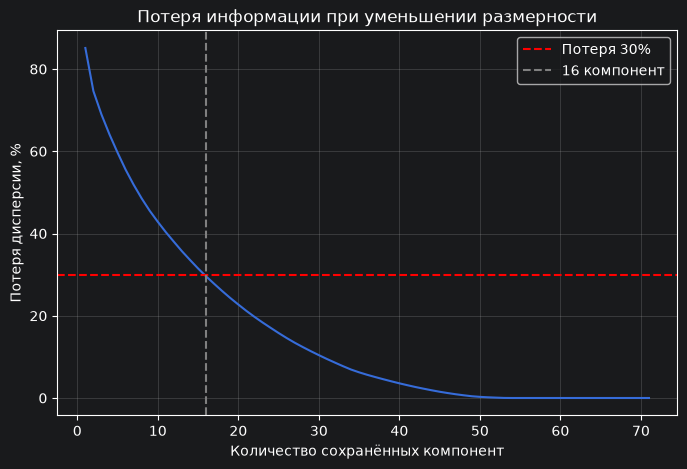

In [18]:
# Находим минимальное число компонент для сохранения 70% дисперсии и строим график
n_70 = int(np.searchsorted(cumulative_variance, 0.70) + 1)

plt.figure(figsize=(8, 5))
plt.plot(components, information_loss * 100)
plt.axhline(30, color='red', linestyle='--', label='Потеря 30%')
plt.axvline(
    n_70, color='gray', linestyle='--',
    label=f'{n_70} компонент'
)
plt.xlabel('Количество сохранённых компонент')
plt.ylabel('Потеря дисперсии, %')
plt.title('Потеря информации при уменьшении размерности')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [19]:
# Сокращаем размерность, обучая PCA только на train
pca_70 = PCA(n_components=n_70, svd_solver='full')

x_train_pca = pca_70.fit_transform(x_train_ready)
x_val_pca = pca_70.transform(x_val_ready)
x_test_pca = pca_70.transform(x_test_ready)

print(x_train_pca.shape, x_val_pca.shape, x_test_pca.shape)

(600, 16) (200, 16) (200, 16)


In [20]:
# Подбираем число кластеров после уменьшения размерности
kmeans_pca_results = []

for k in range(2, 11):
    model = KMeans(
        n_clusters=k,
        n_init=10,
        random_state=42
    )
    model.fit(x_train_pca)
    y_val_pred = model.predict(x_val_pca)

    kmeans_pca_results.append({
        'k': k,
        'silhouette': silhouette_score(x_val_pca, y_val_pred),
        'davies_bouldin': davies_bouldin_score(x_val_pca, y_val_pred)
    })

kmeans_pca_results_df = pd.DataFrame(kmeans_pca_results)
kmeans_pca_results_df

,k,silhouette,davies_bouldin
0,2,0.149891,2.176328
1,3,0.121097,2.230536
2,4,0.099084,2.319165
3,5,0.073716,2.615747
4,6,0.072329,2.529367
5,7,0.072471,2.360001
6,8,0.065183,2.356850
7,9,0.058859,2.436940
8,10,0.061450,2.372581


In [21]:
# После PCA все равно результат лучший k=2 по обоим метрикам
# Теперь подберем GaussianMixture после PCA
gmm_pca_results = []

for k in range(2, 11):
    for covariance in ['full', 'tied', 'diag', 'spherical']:
        model = GaussianMixture(
            n_components=k,
            covariance_type=covariance,
            n_init=5,
            random_state=42
        )
        model.fit(x_train_pca)
        y_val_pred = model.predict(x_val_pca)

        n_labels = np.unique(y_val_pred).size
        silhouette = np.nan
        davies_bouldin = np.nan

        if model.converged_ and 2 <= n_labels < len(y_val_pred):
            silhouette = silhouette_score(x_val_pca, y_val_pred)
            davies_bouldin = davies_bouldin_score(x_val_pca, y_val_pred)

        gmm_pca_results.append({
            'k': k,
            'covariance_type': covariance,
            'silhouette': silhouette,
            'davies_bouldin': davies_bouldin,
            'converged': model.converged_
        })

gmm_pca_results_df = pd.DataFrame(gmm_pca_results)

In [22]:
gmm_pca_results_df.sort_values('silhouette', ascending=False).head(5)

,k,covariance_type,silhouette,davies_bouldin,converged
3,2,spherical,0.157612,2.123353,True
2,2,diag,0.148687,2.190188,True
1,2,tied,0.133683,2.229213,True
7,3,spherical,0.123895,2.210985,True
11,4,spherical,0.104759,2.283760,True


In [23]:
gmm_pca_results_df.sort_values('davies_bouldin').head(5)

,k,covariance_type,silhouette,davies_bouldin,converged
3,2,spherical,0.157612,2.123353,True
19,6,spherical,0.057663,2.146393,True
2,2,diag,0.148687,2.190188,True
7,3,spherical,0.123895,2.210985,True
31,9,spherical,0.054489,2.217978,True


In [24]:
# Обучаем выбранные модели после PCA
kmeans_pca = KMeans(
    n_clusters=2,
    n_init=10,
    random_state=42
)
kmeans_pca.fit(x_train_pca)

gmm_pca = GaussianMixture(
    n_components=2,
    covariance_type='spherical',
    n_init=5,
    random_state=42
)
gmm_pca.fit(x_train_pca)

,"n_components n_components: int, default=1The number of mixture components.",2
,"covariance_type covariance_type: {'full', 'tied', 'diag', 'spherical'}, default='full'String describing the type of covariance parameters to use.Must be one of:- 'full': each component has its own general covariance matrix.- 'tied': all components share the same general covariance matrix.- 'diag': each component has its own diagonal covariance matrix.- 'spherical': each component has its own single variance.For an example of using `covariance_type`, refer to:ref:`sphx_glr_auto_examples_mixture_plot_gmm_selection.py`.",'spherical'
,"n_init n_init: int, default=1The number of initializations to perform. The best results are kept.",5
,"random_state random_state: int, RandomState instance or None, default=NoneControls the random seed given to the method chosen to initialize theparameters (see `init_params`).In addition, it controls the generation of random samples from thefitted distribution (see the method `sample`).Pass an int for reproducible output across multiple function calls.See :term:`Glossary <random_state>`.",42
,"tol tol: float, default=1e-3The convergence threshold. EM iterations will stop when thelower bound average gain is below this threshold.",0.001
,"reg_covar reg_covar: float, default=1e-6Non-negative regularization added to the diagonal of covariance.Allows to assure that the covariance matrices are all positive.",1e-06
,"max_iter max_iter: int, default=100The number of EM iterations to perform.",100
,"init_params init_params: {'kmeans', 'k-means++', 'random', 'random_from_data'}, default='kmeans'The method used to initialize the weights, the means and theprecisions.String must be one of:- 'kmeans' : responsibilities are initialized using kmeans.- 'k-means++' : use the k-means++ method to initialize.- 'random' : responsibilities are initialized randomly.- 'random_from_data' : initial means are randomly selected data points... versionchanged:: v1.1 `init_params` now accepts 'random_from_data' and 'k-means++' as initialization methods.",'kmeans'
,"weights_init weights_init: array-like of shape (n_components, ), default=NoneThe user-provided initial weights.If it is None, weights are initialized using the `init_params` method.",None
,"means_init means_init: array-like of shape (n_components, n_features), default=NoneThe user-provided initial means,If it is None, means are initialized using the `init_params` method.",None
,"precisions_init precisions_init: array-like, default=NoneThe user-provided initial precisions (inverse of the covariancematrices).If it is None, precisions are initialized using the 'init_params'method.The shape depends on 'covariance_type':: (n_components,) if 'spherical', (n_features, n_features) if 'tied', (n_components, n_features) if 'diag', (n_components, n_features, n_features) if 'full'",None


In [25]:
# Оцениваем модели до и после PCA на тестовой выборке
models = {
    'KMeans full': (kmeans_full, x_test_ready),
    'GMM full': (gmm_full, x_test_ready),
    'KMeans PCA': (kmeans_pca, x_test_pca),
    'GMM PCA': (gmm_pca, x_test_pca)
}

test_results = []
test_predictions = {}

for name, (model, features) in models.items():
    labels = model.predict(features)
    test_predictions[name] = labels

    n_labels = np.unique(labels).size
    silhouette = np.nan
    davies_bouldin = np.nan

    if 2 <= n_labels < len(labels):
        silhouette = silhouette_score(features, labels)
        davies_bouldin = davies_bouldin_score(features, labels)

    test_results.append({
        'Model': name,
        'Features': features.shape[1],
        'Clusters': n_labels,
        'Silhouette': silhouette,
        'Davies–Bouldin': davies_bouldin
    })

comparison = pd.DataFrame(test_results)
comparison

,Model,Features,Clusters,Silhouette,Davies–Bouldin
0,KMeans full,71,2,0.101613,2.871828
1,GMM full,71,2,0.101613,2.871828
2,KMeans PCA,16,2,0.138684,2.331630
3,GMM PCA,16,2,0.153854,2.232519


In [26]:
# Сравниваем назначения одинаковых тестовых объектов до и после PCA
ari_comparison = pd.DataFrame({
    'Model': ['KMeans', 'GaussianMixture'],
    'ARI before vs after PCA': [
        adjusted_rand_score(
            test_predictions['KMeans full'],
            test_predictions['KMeans PCA']
        ),
        adjusted_rand_score(
            test_predictions['GMM full'],
            test_predictions['GMM PCA']
        )
    ]
})

ari_comparison

,Model,ARI before vs after PCA
0,KMeans,0.939604
1,GaussianMixture,0.860337


In [27]:
# Точная потеря дисперсии
retained_variance = pca_70.explained_variance_ratio_.sum()

print(f'Сохранено дисперсии: {retained_variance:.2%}\n'
      f'Потеряно дисперсии: {1 - retained_variance:.2%}')

Сохранено дисперсии: 70.42%
Потеряно дисперсии: 29.58%


По обеим метрикам для KMeans и GaussianMixture выбраны два кластера до и после PCA. Размерность сокращена с 71 до 16 при потере 29,58% дисперсии. Разбиения в основном сохранились: ARI - 0,9396 для KMeans и 0,8603 для GaussianMixture. После PCA GMM показала лучшие тестовые метрики, однако разделённость кластеров остаётся слабой.